# Credit Risk Modeling Project (LendingClub)

This project builds a complete credit risk pipeline including:
- Data extraction & cleaning
- Feature engineering
- PD model (Logistic Regression)
- Machine Learning model (XGBoost)
- Scorecard generation
- Credit decision strategy

In [41]:
import os
import sys
sys.path.append(os.path.abspath(".."))
os.makedirs("../outputs", exist_ok=True)
from src.extraction import extract_selected_columns
from src.clean import clean_lendingclub
from src.feature_engineering import feature_engineering
from src.pd_model import train_pd_model
from src.ml_model import train_ml_model
from src.scorecard import generate_scorecard, assign_rating, credit_decision

## 1. Data Extraction

We load LendingClub loan-level data and extract relevant columns for credit risk modeling.

In [42]:
path = "../data/appl_accepted_20072019Q3.csv"

df_raw = extract_selected_columns(path)

df_raw.head()


=== Column Mapping ===
loan_status  -->  loan_status
annual_inc  -->  annual_inc
emp_length  -->  emp_length
home_ownership  -->  home_ownership
dti  -->  dti
revol_util  -->  revol_util
open_acc  -->  open_acc
total_acc  -->  total_acc
delinq_2yrs  -->  delinq_2yrs
loan_amnt  -->  loan_amnt
term  -->  term
int_rate  -->  int_rate
purpose  -->  purpose
issue_d  -->  issue_d
id  -->  id

Extraction finished. Shape: (2650550, 15)


,id,loan_amnt,term,int_rate,emp_length,home_ownership,annual_inc,issue_d,loan_status,purpose,dti,delinq_2yrs,open_acc,revol_util,total_acc
0,68407277,3600.0,36 months,13.99,10+ years,MORTGAGE,55000.0,Dec-2015,Fully Paid,debt_consolidation,5.91,0.0,7.0,29.7,13.0
1,68355089,24700.0,36 months,11.99,10+ years,MORTGAGE,65000.0,Dec-2015,Fully Paid,small_business,16.06,1.0,22.0,19.2,38.0
2,68341763,20000.0,60 months,10.78,10+ years,MORTGAGE,63000.0,Dec-2015,Fully Paid,home_improvement,10.78,0.0,6.0,56.2,18.0
3,66310712,35000.0,60 months,14.85,10+ years,MORTGAGE,110000.0,Dec-2015,Current,debt_consolidation,17.06,0.0,13.0,11.6,17.0
4,68476807,10400.0,60 months,22.45,3 years,MORTGAGE,104433.0,Dec-2015,Fully Paid,major_purchase,25.37,1.0,12.0,64.5,35.0


## 2. Data Cleaning

We clean missing values, handle data types, and prepare the dataset for modeling.

In [43]:
df_clean = clean_lendingclub(df_raw)

df_clean.head()

,loan_amnt,term,int_rate,emp_length,home_ownership,annual_inc,issue_d,loan_status,purpose,dti,delinq_2yrs,open_acc,revol_util,total_acc,default
0,3600.0,36 months,13.99,10.0,MORTGAGE,55000.0,2015-12-01,Fully Paid,debt_consolidation,5.91,0.0,7.0,29.7,13.0,0
1,24700.0,36 months,11.99,10.0,MORTGAGE,65000.0,2015-12-01,Fully Paid,small_business,16.06,1.0,22.0,19.2,38.0,0
2,20000.0,60 months,10.78,10.0,MORTGAGE,63000.0,2015-12-01,Fully Paid,home_improvement,10.78,0.0,6.0,56.2,18.0,0
4,10400.0,60 months,22.45,3.0,MORTGAGE,104433.0,2015-12-01,Fully Paid,major_purchase,25.37,1.0,12.0,64.5,35.0,0
5,11950.0,36 months,13.44,4.0,RENT,34000.0,2015-12-01,Fully Paid,debt_consolidation,10.20,0.0,5.0,68.4,6.0,0


## 3. Save Clean Dataset

In [44]:
clean_path = "../outputs/lendingclub_clean.parquet"

df_clean.to_parquet(clean_path, index=False)

## 4. Feature Engineering

We split the dataset into training and testing sets and create model-ready features.

In [45]:
X_train, X_test, y_train, y_test = feature_engineering(df_clean)

print(X_train.shape, X_test.shape)

X_train.to_parquet("../outputs/X_train.parquet", index=False)
X_test.to_parquet("../outputs/X_test.parquet", index=False)

y_train.to_frame("default").to_parquet("../outputs/y_train.parquet", index=False)
y_test.to_frame("default").to_parquet("../outputs/y_test.parquet", index=False)


(1108721, 30) (277181, 30)


## 5. PD Model (Logistic Regression)

We train a baseline probability of default (PD) model.

AUC Train: 0.7055
AUC Test: 0.7069


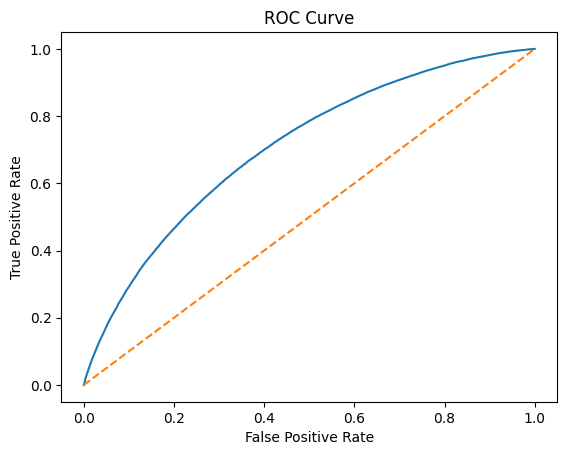

KS (from curve): 0.3015


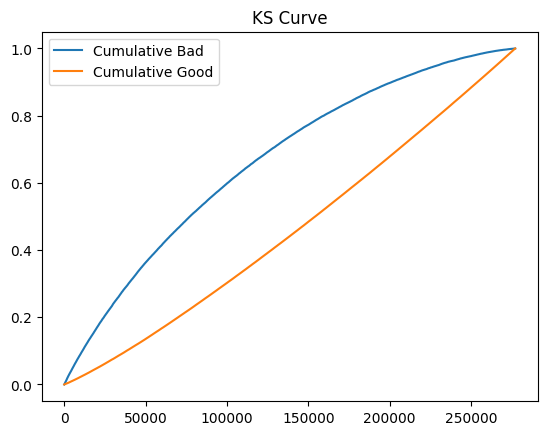


Top Positive Risk Factors:
                       feature  coefficient
7                     int_rate     0.455011
9                         term     0.204615
10                  issue_year     0.136577
3                     open_acc     0.119029
6                loan_amnt_log     0.117066
1                          dti     0.114380
16         home_ownership_RENT     0.099816
2                   revol_util     0.067749
18  purpose_debt_consolidation     0.064651
27      purpose_small_business     0.060552

Top Negative Risk Factors:
                     feature  coefficient
15        home_ownership_OWN     0.009045
14      home_ownership_OTHER     0.007809
26  purpose_renewable_energy     0.007127
21             purpose_house     0.001194
13       home_ownership_NONE    -0.002456
29           purpose_wedding    -0.009708
8                 emp_length    -0.012673
12   home_ownership_MORTGAGE    -0.090119
4                  total_acc    -0.091713
0             log_annual_inc    -0.14144

{'auc_train': 0.7054539413412275,
 'auc_test': 0.7069097921633469,
 'ks': np.float64(0.3015394935627466)}

In [46]:
model, scaler, metrics = train_pd_model(X_train, X_test, y_train, y_test)

metrics

## 6. Machine Learning Model (XGBoost)

We compare Logistic Regression with XGBoost.

[XGBoost] AUC Train: 0.7203
[XGBoost] AUC Test: 0.7202


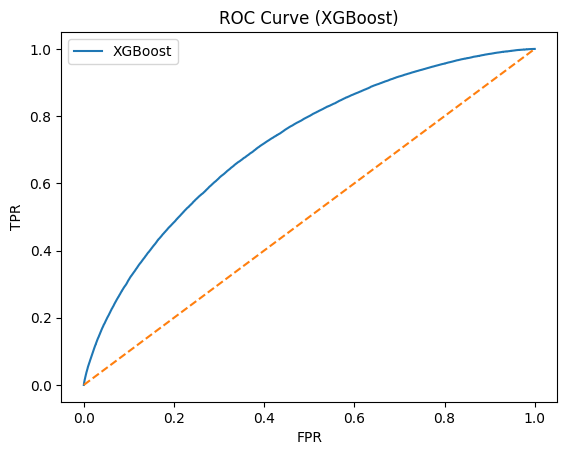

[XGBoost] KS: 0.3209

[XGBoost] Top Features:
                    feature  importance
7                  int_rate    0.418483
9                      term    0.148835
16      home_ownership_RENT    0.085446
12  home_ownership_MORTGAGE    0.060269
1                       dti    0.049931
10               issue_year    0.044942
6             loan_amnt_log    0.028272
0            log_annual_inc    0.027316
11              issue_month    0.021766
8                emp_length    0.015529


{'auc_train': 0.7203402209608859,
 'auc_test': 0.7202315955286169,
 'ks': np.float64(0.3209364953475877)}

In [47]:
ml_model, ml_metrics = train_ml_model(X_train, X_test, y_train, y_test)

ml_metrics

## 7. Model Comparison

In [48]:
print(f"Logistic AUC: {metrics['auc_test']:.4f}")
print(f"XGBoost  AUC: {ml_metrics['auc_test']:.4f}")

print(f"Logistic KS: {metrics['ks']:.4f}")
print(f"XGBoost  KS: {ml_metrics['ks']:.4f}")

Logistic AUC: 0.7069
XGBoost  AUC: 0.7202
Logistic KS: 0.3015
XGBoost  KS: 0.3209


## 8. Scorecard Generation

We convert predicted PD into a credit score and rating system.

In [49]:
X_test_scaled = scaler.transform(X_test)

score_df = generate_scorecard(model, X_test_scaled)

score_df["Rating"] = score_df["Score"].apply(assign_rating)

score_df.to_parquet("../outputs/scorecard.parquet", index=False)

score_df.head()

,PD,Score,Rating
0,0.282746,667.148878,B
1,0.081251,774.960491,A
2,0.153799,722.997672,A
3,0.259336,675.699679,B
4,0.434631,618.970125,C


## 9. Credit Decision Strategy

We define approval, review, and rejection rules based on credit score.

In [50]:
score_df["Decision"] = score_df["Score"].apply(credit_decision)

score_df["Decision"].value_counts(normalize=True)

Decision
Approve    0.620136
Review     0.253942
Reject     0.125921
Name: proportion, dtype: float64

## 10. Risk Segmentation Validation

We evaluate default rates across decision groups.

In [51]:
result = score_df.copy()
result["default"] = y_test.values

result.groupby("Decision")["default"].mean()

Decision
Approve    0.121362
Reject     0.425895
Review     0.271041
Name: default, dtype: float64

## 11. Conclusion

- The model achieves strong predictive performance (AUC & KS)
- Scorecard provides interpretable credit risk ranking
- Decision strategy effectively separates risk levels

Default rates increase significantly across segments:
- Approve → lowest risk
- Review → medium risk
- Reject → highest risk

This demonstrates the model's ability to support real-world credit decisions.